<a href="https://colab.research.google.com/github/miriamamin1213-ux/FinalModels/blob/main/GPT2LLMhancockLR1e-3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Device: cuda


Downloading...
From: https://drive.google.com/uc?id=1F_kngwHn6KkOQqSwtYXCaF-bT8DZt__Q
To: /content/clinical_data.json
100%|██████████| 810k/810k [00:00<00:00, 12.6MB/s]
Downloading...
From: https://drive.google.com/uc?id=1KY3NS9q3lfodf-t3g92S1JE3Vqcl6o3F
To: /content/pathological_data.json
100%|██████████| 458k/458k [00:00<00:00, 7.20MB/s]


Patients: 332
Training distribution: {0: 152, 1: 113}
Test distribution: {0: 39, 1: 28}


tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

GPT-2 hidden size: 768 | Layers: 12 | Heads: 12
Class weights: tensor([0.8717, 1.1726], device='cuda:0')
Epoch 50/500 | Train Loss=0.0584 | Test Loss=0.4330 | BA=0.6035 | AUC=0.6520
Epoch 100/500 | Train Loss=0.0193 | Test Loss=0.6529 | BA=0.6039 | AUC=0.6694
Epoch 150/500 | Train Loss=0.0103 | Test Loss=1.0152 | BA=0.5582 | AUC=0.6548
Epoch 200/500 | Train Loss=0.0185 | Test Loss=0.8305 | BA=0.6603 | AUC=0.7079
Epoch 250/500 | Train Loss=0.0169 | Test Loss=0.4819 | BA=0.7340 | AUC=0.7958
Epoch 300/500 | Train Loss=0.0117 | Test Loss=0.9196 | BA=0.6140 | AUC=0.6877
Epoch 350/500 | Train Loss=0.0028 | Test Loss=1.1413 | BA=0.6603 | AUC=0.7262
Epoch 400/500 | Train Loss=0.0469 | Test Loss=0.6347 | BA=0.7317 | AUC=0.7299
Epoch 450/500 | Train Loss=0.0321 | Test Loss=0.7464 | BA=0.6598 | AUC=0.6749
Epoch 500/500 | Train Loss=0.0330 | Test Loss=0.9092 | BA=0.6296 | AUC=0.6364

===== Best Test Loss =====
              precision    recall  f1-score   support

HPV Negative     0.8387    0.6667

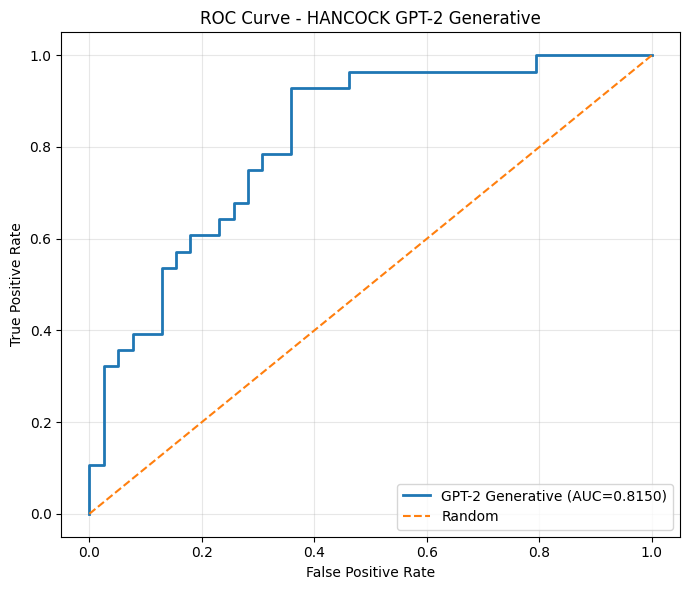


Invalid generated predictions: 6
              precision    recall  f1-score   support

HPV Negative     0.7222    0.7879    0.7536        33
HPV Positive     0.7200    0.6429    0.6792        28

    accuracy                         0.7213        61
   macro avg     0.7211    0.7154    0.7164        61
weighted avg     0.7212    0.7213    0.7195        61

Generated-label BA: 0.7153679653679654
Generated-label F1: 0.6792452830188679

Saved results to: /content/ROC_HANCOCK_GPT2
Optimizer: AdamW | Learning rate: 0.00002 | Weight decay: 0.0001
Gradient clipping: None | Class weights: training set only
Max length: 256 | Batch size: 8 | Epochs: 500


In [1]:
# ============================================================
# GPT-2 GENERATIVE HPV PREDICTION - HANCOCK
# ============================================================
import os, random, json, gdown
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from pathlib import Path
from torch.utils.data import Dataset, DataLoader
from transformers import GPT2Tokenizer, GPT2LMHeadModel
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, balanced_accuracy_score,
    f1_score, roc_auc_score, roc_curve
)

# 1. Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# 2. Load HANCOCK data
for file, file_id in [
    ("clinical_data.json", "1F_kngwHn6KkOQqSwtYXCaF-bT8DZt__Q"),
    ("pathological_data.json", "1KY3NS9q3lfodf-t3g92S1JE3Vqcl6o3F")
]:
    if not os.path.exists(file):
        result = gdown.download(id=file_id, output=file, quiet=False)
        if result is None or not os.path.exists(file):
            raise FileNotFoundError(f"Could not download {file}; upload it manually.")

with open("clinical_data.json") as f:
    clinical = pd.DataFrame(json.load(f))
with open("pathological_data.json") as f:
    pathology = pd.DataFrame(json.load(f))

df = clinical.merge(pathology, on="patient_id", how="inner")
df = df[df["hpv_association_p16"].isin(["positive", "negative"])].copy()
df["HPV"] = df["hpv_association_p16"].map({"negative": 0, "positive": 1})

features = [
    "age_at_initial_diagnosis", "sex", "smoking_status",
    "primarily_metastasis", "first_treatment_intent",
    "first_treatment_modality", "days_to_first_treatment",
    "adjuvant_treatment_intent", "adjuvant_radiotherapy",
    "adjuvant_radiotherapy_modality", "adjuvant_systemic_therapy",
    "adjuvant_systemic_therapy_modality", "adjuvant_radiochemotherapy",
    "primary_tumor_site", "pT_stage", "pN_stage", "histologic_type",
    "number_of_positive_lymph_nodes", "number_of_resected_lymph_nodes",
    "perinodal_invasion", "lymphovascular_invasion_L",
    "vascular_invasion_V", "perineural_invasion_Pn",
    "resection_status", "infiltration_depth_in_mm"
]
df = df.dropna(subset=["HPV"]).copy()

# 3. Stratified split and train-only imputation
train_df, test_df = train_test_split(
    df[features + ["HPV"]], test_size=0.20,
    random_state=SEED, stratify=df["HPV"]
)
train_df, test_df = train_df.copy(), test_df.copy()

for col in features:
    fill_value = (
        train_df[col].mode().iloc[0]
        if train_df[col].dtype == object
        else train_df[col].median()
    )
    train_df[col] = train_df[col].fillna(fill_value)
    test_df[col] = test_df[col].fillna(fill_value)

y_train = train_df["HPV"].astype(int).to_numpy()
y_test = test_df["HPV"].astype(int).to_numpy()

# 4. HANCOCK clinical narratives
def patient_to_text(row):
    return (
        "You are a clinician specialising in head and neck cancer. "
        "Predict the patient's Human Papillomavirus (HPV) status. "
        f"Age at diagnosis: {row['age_at_initial_diagnosis']}. "
        f"Sex: {row['sex']}. Smoking status: {row['smoking_status']}. "
        f"Primary metastasis status: {row['primarily_metastasis']}. "
        f"Primary tumour site: {row['primary_tumor_site']}. "
        f"Histologic type: {row['histologic_type']}. "
        f"Pathological T stage: {row['pT_stage']}. "
        f"Pathological N stage: {row['pN_stage']}. "
        f"Positive lymph nodes: {row['number_of_positive_lymph_nodes']}. "
        f"Resected lymph nodes: {row['number_of_resected_lymph_nodes']}. "
        f"Perinodal invasion: {row['perinodal_invasion']}. "
        f"Lymphovascular invasion: {row['lymphovascular_invasion_L']}. "
        f"Vascular invasion: {row['vascular_invasion_V']}. "
        f"Perineural invasion: {row['perineural_invasion_Pn']}. "
        f"Resection status: {row['resection_status']}. "
        f"Infiltration depth: {row['infiltration_depth_in_mm']} mm. "
        f"First treatment intent: {row['first_treatment_intent']}. "
        f"First treatment modality: {row['first_treatment_modality']}. "
        f"Days to first treatment: {row['days_to_first_treatment']}. "
        f"Adjuvant treatment intent: {row['adjuvant_treatment_intent']}. "
        f"Adjuvant radiotherapy: {row['adjuvant_radiotherapy']}. "
        f"Adjuvant radiotherapy modality: {row['adjuvant_radiotherapy_modality']}. "
        f"Adjuvant systemic therapy: {row['adjuvant_systemic_therapy']}. "
        f"Adjuvant systemic therapy modality: {row['adjuvant_systemic_therapy_modality']}. "
        f"Adjuvant radiochemotherapy: {row['adjuvant_radiochemotherapy']}. "
        "Respond with exactly one label: HPV Positive or HPV Negative."
    )

train_texts = [patient_to_text(r) for _, r in train_df.iterrows()]
test_texts = [patient_to_text(r) for _, r in test_df.iterrows()]
train_targets = ["HPV Positive" if y == 1 else "HPV Negative" for y in y_train]

print("Patients:", len(df))
print("Training distribution:", pd.Series(y_train).value_counts().sort_index().to_dict())
print("Test distribution:", pd.Series(y_test).value_counts().sort_index().to_dict())

# 5. GPT-2 tokenizer and generative dataset
MODEL_NAME = "openai-community/gpt2"
MAX_LENGTH, BATCH_SIZE, EPOCHS = 256, 8, 500

tokenizer = GPT2Tokenizer.from_pretrained(MODEL_NAME)
tokenizer.pad_token = tokenizer.eos_token

class GPT2GenerationDataset(Dataset):
    def __init__(self, texts, targets, labels, max_length=256):
        self.items = []
        for text, target, label in zip(texts, targets, labels):
            prompt_ids = tokenizer.encode(text, add_special_tokens=False)
            target_ids = tokenizer.encode(" " + target, add_special_tokens=False)
            target_ids += [tokenizer.eos_token_id]
            prompt_ids = prompt_ids[:max_length - len(target_ids)]
            ids = prompt_ids + target_ids
            loss_labels = [-100] * len(prompt_ids) + target_ids
            pad = max_length - len(ids)
            self.items.append((
                ids + [tokenizer.pad_token_id] * pad,
                [1] * len(ids) + [0] * pad,
                loss_labels + [-100] * pad,
                int(label)
            ))

    def __len__(self):
        return len(self.items)

    def __getitem__(self, i):
        ids, mask, labels, cls = self.items[i]
        return {
            "input_ids": torch.tensor(ids),
            "attention_mask": torch.tensor(mask),
            "labels": torch.tensor(labels),
            "class_label": torch.tensor(cls, dtype=torch.long)
        }

train_dataset = GPT2GenerationDataset(
    train_texts, train_targets, y_train, MAX_LENGTH
)
test_targets = ["HPV Positive" if y == 1 else "HPV Negative" for y in y_test]
test_dataset = GPT2GenerationDataset(
    test_texts, test_targets, y_test, MAX_LENGTH
)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

# 6. Generative GPT-2 model
model = GPT2LMHeadModel.from_pretrained(MODEL_NAME).to(device)
model.config.pad_token_id = tokenizer.pad_token_id
print("GPT-2 hidden size:", model.config.n_embd,
      "| Layers:", model.config.n_layer, "| Heads:", model.config.n_head)

# 7. Training-only class weights and optimizer
class_counts = np.bincount(y_train, minlength=2)
class_weights = torch.tensor(
    len(y_train) / (2 * class_counts),
    dtype=torch.float32, device=device
)
print("Class weights:", class_weights)

optimizer = torch.optim.AdamW(
    model.parameters(), lr=1e-3, weight_decay=1e-4
)

def weighted_generation_loss(logits, labels, class_labels):
    shift_logits = logits[:, :-1, :].contiguous()
    shift_labels = labels[:, 1:].contiguous()
    token_loss = nn.CrossEntropyLoss(reduction="none")(
        shift_logits.reshape(-1, shift_logits.size(-1)),
        shift_labels.reshape(-1)
    ).view(shift_labels.size(0), -1)
    valid = (shift_labels != -100).float()
    example_loss = (token_loss * valid).sum(1) / valid.sum(1).clamp(min=1)
    return (example_loss * class_weights[class_labels]).mean()

# 8. Likelihood-based continuous HPV scores
# Positive score favours HPV Positive.
def get_hpv_scores(prompts, batch_size=8):
    model.eval()
    scores = []
    with torch.no_grad():
        for prompt in prompts:
            prompt_ids = tokenizer.encode(
                prompt, add_special_tokens=False
            )[:MAX_LENGTH - 6]
            losses = []
            for candidate in ["HPV Positive", "HPV Negative"]:
                target_ids = tokenizer.encode(" " + candidate, add_special_tokens=False)
                ids = prompt_ids + target_ids
                inputs = torch.tensor([ids], device=device)
                logits = model(input_ids=inputs).logits
                start = len(prompt_ids) - 1
                candidate_logits = logits[
                    0, start:start + len(target_ids), :
                ]
                targets = inputs[0, len(prompt_ids):]
                losses.append(nn.functional.cross_entropy(
                    candidate_logits, targets, reduction="mean"
                ).item())
            scores.append(losses[1] - losses[0])
    return np.asarray(scores)

# 9. Training (same selection approach as HECKTOR)
out_dir = Path("ROC_HANCOCK_GPT2")
out_dir.mkdir(parents=True, exist_ok=True)
paths = {
    "loss": out_dir / "best_model_loss.pth",
    "ba": out_dir / "best_model_ba.pth",
    "auc": out_dir / "best_model_auc.pth"
}
best = {"loss": float("inf"), "ba": -1, "auc": -1}

for epoch in range(EPOCHS):
    model.train()
    train_total = 0
    for batch in train_loader:
        ids = batch["input_ids"].to(device)
        mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)
        classes = batch["class_label"].to(device)

        optimizer.zero_grad(set_to_none=True)
        logits = model(input_ids=ids, attention_mask=mask).logits
        loss = weighted_generation_loss(logits, labels, classes)
        loss.backward()
        optimizer.step()
        train_total += loss.item()

    model.eval()
    test_total = 0
    with torch.no_grad():
        for batch in test_loader:
            ids = batch["input_ids"].to(device)
            mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)
            classes = batch["class_label"].to(device)
            logits = model(input_ids=ids, attention_mask=mask).logits
            test_total += weighted_generation_loss(logits, labels, classes).item()

    test_loss = test_total / len(test_loader)
    scores = get_hpv_scores(test_texts, BATCH_SIZE)
    pred = (scores > 0).astype(int)
    ba = balanced_accuracy_score(y_test, pred)
    auc = roc_auc_score(y_test, scores)

    for key, value in [("loss", test_loss), ("ba", ba), ("auc", auc)]:
        improved = value < best[key] if key == "loss" else value > best[key]
        if improved:
            best[key] = value
            torch.save(model.state_dict(), paths[key])

    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch+1}/{EPOCHS} | "
              f"Train Loss={train_total/len(train_loader):.4f} | "
              f"Test Loss={test_loss:.4f} | BA={ba:.4f} | AUC={auc:.4f}")

# 10. Evaluate checkpoints and save ROC outputs
def evaluate_checkpoint(path, name):
    model.load_state_dict(torch.load(path, map_location=device))
    scores = get_hpv_scores(test_texts, BATCH_SIZE)
    pred = (scores > 0).astype(int)
    ba = balanced_accuracy_score(y_test, pred)
    f1 = f1_score(y_test, pred, zero_division=0)
    auc = roc_auc_score(y_test, scores)
    print(f"\n===== {name} =====")
    print(classification_report(
        y_test, pred, labels=[0, 1],
        target_names=["HPV Negative", "HPV Positive"],
        digits=4, zero_division=0
    ))
    print(f"Balanced Accuracy: {ba:.4f} | F1: {f1:.4f} | AUC: {auc:.4f}")
    return scores, pred, ba, f1, auc

results = {}
for key, name in [
    ("loss", "Best Test Loss"),
    ("ba", "Best Balanced Accuracy"),
    ("auc", "Best ROC-AUC")
]:
    results[key] = evaluate_checkpoint(paths[key], name)

scores, pred, ba, f1, auc = results["auc"]
fpr, tpr, thresholds = roc_curve(y_test, scores)

pd.DataFrame({
    "FPR": fpr, "TPR": tpr, "Threshold": thresholds
}).to_csv(out_dir / "roc_coordinates_best_auc.csv", index=False)

pd.DataFrame({
    "True_Label": y_test,
    "HPV_Positive_Score": scores,
    "Predicted_Label": pred
}).to_csv(out_dir / "roc_patient_scores_best_auc.csv", index=False)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, linewidth=2, label=f"GPT-2 Generative (AUC={auc:.4f})")
plt.plot([0, 1], [0, 1], "--", linewidth=1.5, label="Random")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - HANCOCK GPT-2 Generative")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(out_dir / "roc_curve_best_auc.png", dpi=300, bbox_inches="tight")
plt.show()

pd.DataFrame([
    {"Checkpoint": name, "BA": r[2], "F1": r[3], "AUC": r[4]}
    for name, r in [
        ("Best Loss", results["loss"]),
        ("Best BA", results["ba"]),
        ("Best AUC", results["auc"])
    ]
]).to_csv(out_dir / "evaluation_summary.csv", index=False)

# 11. Actual generated labels
def generate_prediction(prompt):
    enc = tokenizer(prompt, return_tensors="pt", truncation=True,
                    max_length=MAX_LENGTH).to(device)
    with torch.no_grad():
        generated = model.generate(
            **enc, max_new_tokens=5, do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )
    return tokenizer.decode(
        generated[0, enc["input_ids"].shape[1]:],
        skip_special_tokens=True
    ).strip()

def extract_hpv_label(text):
    text = " ".join(text.lower().strip().split())
    return 1 if text == "hpv positive" else 0 if text == "hpv negative" else -1

model.load_state_dict(torch.load(paths["auc"], map_location=device))
generated = [generate_prediction(p) for p in test_texts]
generated_labels = np.array([extract_hpv_label(x) for x in generated])

pd.DataFrame({
    "True_Label": y_test,
    "Generated_Text": generated,
    "Generated_Label": generated_labels
}).to_csv(out_dir / "generated_predictions.csv", index=False)

valid = generated_labels != -1
print("\nInvalid generated predictions:", int((~valid).sum()))
if valid.any():
    print(classification_report(
        y_test[valid], generated_labels[valid],
        labels=[0, 1], target_names=["HPV Negative", "HPV Positive"],
        digits=4, zero_division=0
    ))
    print("Generated-label BA:",
          balanced_accuracy_score(y_test[valid], generated_labels[valid]))
    print("Generated-label F1:",
          f1_score(y_test[valid], generated_labels[valid], zero_division=0))

print("\nSaved results to:", out_dir.resolve())
print("Optimizer: AdamW | Learning rate: 0.00002 | Weight decay: 0.0001")
print("Gradient clipping: None | Class weights: training set only")
print("Max length:", MAX_LENGTH, "| Batch size:", BATCH_SIZE, "| Epochs:", EPOCHS)